# GPT-2 small activation atlas: exploring stage 1

Reads the outputs of `python -m atlas` (see `docs/atlas-design.md`) and looks at what they say about GPT-2 small.
Build them first with `run-atlas`: 1M tokens, one 127-token window from each of ~8k documents across two OpenWebText
files, run as 8 shards for bootstrap errors; about 5 minutes on an M4.

1. Residual-stream geometry: how variance and effective dimension grow with depth
2. MLP neurons: firing rates and peak activations by layer
3. A single neuron: summary, activation histogram and top contexts
4. Statistical errors (bootstrap over shards) and the corpus systematic (file vs file)
5. Regression check: stored exemplar pointers reproduce on recompute

All statistics exclude position 0 (BOS) and are conditional on OpenWebText and positions 1–127.

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import torch
import pandas as pd
from atlas import HFGPT2, bootstrap_weights, pooled_moments

ATLAS = Path("../results/atlas")
manifest = json.loads((ATLAS / "manifest.json").read_text())
neurons = duckdb.sql(f"select * from '{ATLAS / 'neurons.parquet'}'").df()
topk = duckdb.sql(f"select * from '{ATLAS / 'topk.parquet'}'").df()
resid = np.load(ATLAS / "resid.npz")
hists = np.load(ATLAS / "histograms.npz")
tokens = np.load(ATLAS / "tokens.npy", mmap_mode="r")

# Categorical slots 1-4 and text inks of the dataviz default palette, as in ioi_hydra.ipynb.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
def tidy(ax):
    ax.grid(axis="y", color=GRID, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

print(f"{manifest['n_rows']:,} rows x {manifest['seq_len']} tokens from {manifest['n_docs']:,} documents "
      f"({manifest['dataset']} files {manifest['files']}, at most {manifest['max_windows_per_doc']} window per document)")
print(f"{neurons['n'].iloc[0]:,} tokens per unit; {len(neurons):,} units; {len(topk):,} top-k exemplars")

7,813 rows x 128 tokens from 909 docs (Skylion007/openwebtext shard 0)
992,251 tokens per unit; 46,848 units; 936,960 top-k exemplars


## 1. Residual-stream geometry

From the per-layer covariance in `resid.npz` ("layer 12" is the final residual stream, the input to `ln_final`).

- **Total variance**, the trace of the covariance: how much the stream's spread grows with depth.
- **Effective dimension**, the participation ratio $(\sum_i \lambda_i)^2 / \sum_i \lambda_i^2$ of the eigenvalues: about
  1 if one direction carries everything, 768 if variance is spread evenly.
- **Largest single basis dimension's share of variance**: the residual basis is not privileged in general, but GPT-2 is
  known to have a few outlier dimensions (447 among them).

*Expect:* variance growing roughly exponentially with depth, and a low effective dimension where outlier dimensions dominate.

layer  total var  eff. dim  dims for 90%  top basis dim (share)
    0       11.7      14.3           411   479 (2%)
    1     1029.4      31.3           316   480 (8%)
    2     1317.1      46.5           329   480 (7%)
    3     1656.9      72.3           380   480 (5%)
    4     2147.6     105.1           426   480 (4%)
    5     2654.9     133.2           451   480 (3%)
    6     3363.3     153.1           470   480 (3%)
    7     4313.8     167.6           487   480 (2%)
    8     5828.4     171.5           502   447 (2%)
    9     8064.6     172.3           508   447 (2%)
   10    11853.9     155.4           515   447 (2%)
   11    18915.5     100.8           508   496 (3%)
   12    55405.4       6.8           343   496 (11%)


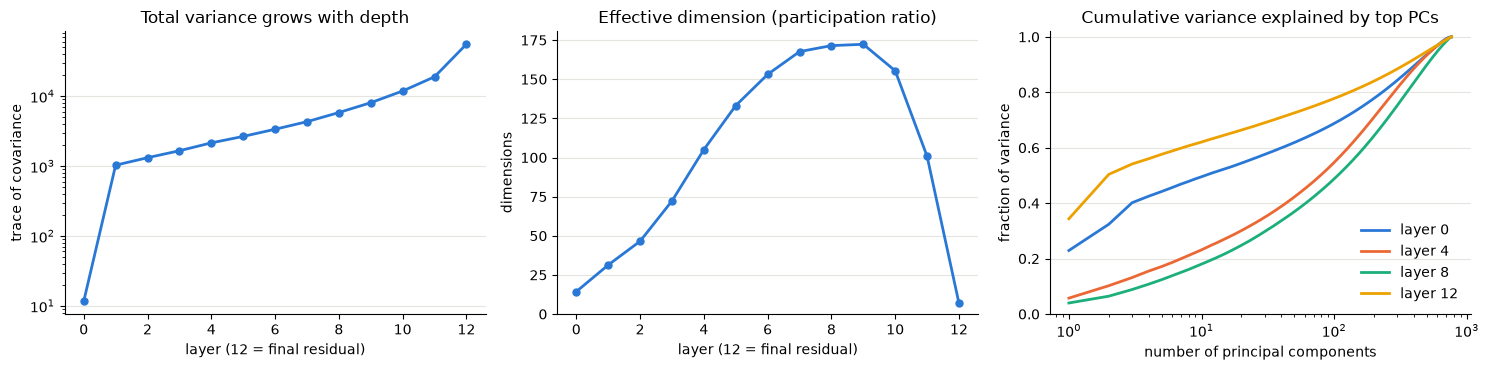

In [2]:
layers, cov = resid["layer"], resid["cov"]
eig = np.linalg.eigvalsh(cov)[:, ::-1]  # [13, 768], descending
total, pr = resid["total_var"], resid["pr"]  # = eig.sum(1) and eig.sum(1)**2 / (eig**2).sum(1)
total_err, pr_err = resid["total_var_err"], resid["pr_err"]  # bootstrap over shards
diag = np.diagonal(cov, axis1=1, axis2=2)
top_dim, top_share = diag.argmax(1), diag.max(1) / total
dims90 = (np.cumsum(eig, 1) / total[:, None] < 0.9).sum(1) + 1

print("layer  total var        eff. dim      dims for 90%  top basis dim (share)")
for l in layers:
    print(f"{l:5d}  {total[l]:8.1f} ± {total_err[l]:<5.1f}  {pr[l]:5.1f} ± {pr_err[l]:<4.1f}  {dims90[l]:12d}  {top_dim[l]:4d} ({top_share[l]:.0%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].errorbar(layers, total, yerr=total_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[0].set(yscale="log", title="Total variance grows with depth", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].errorbar(layers, pr, yerr=pr_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[1].set(title="Effective dimension (participation ratio)", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
for i, l in enumerate([0, 4, 8, 12]):
    axes[2].plot(np.arange(1, 769), np.cumsum(eig[l]) / total[l], color=C[i], lw=2, label=f"layer {l}")
axes[2].set(xscale="log", title="Cumulative variance explained by top PCs", xlabel="number of principal components", ylabel="fraction of variance", ylim=(0, 1.02))
axes[2].legend(frameon=False, loc="lower right")
for ax in axes:
    tidy(ax)
plt.tight_layout()

**Reading it.** The first block multiplies the stream's variance by about 90 (layer 0 is the embedding alone), and it
grows steadily after that, another 3× in the last block. The effective dimension rises from 14 to about 170 by layers
7–9, then collapses to about 7 at the final residual stream, where a handful of directions carry most of the variance
(the top principal component alone carries about a third). In the basis, dimension 480 stands out early (7.5% of the
variance at layer 1, falling to 2% by layer 7); from layer 7 to 11 no dimension carries more than about 2.5%, so which
one is largest there is not meaningful. At the final residual, dimensions 496, 430 and 36 carry 11%, 8% and 8%. The
bootstrap errors are tiny: the effective dimension is known to better than ±0.5 at every layer.

## 2. MLP neurons

Each neuron's firing rate (fraction of tokens with post-GELU activation > 0) and its peak activation, summarized per
layer as the median with a 10th–90th percentile band. Rarely-firing neurons are those with a firing rate below 1e-4,
fewer than about 100 tokens in 1M.

*Expect:* early layers to hold most of the rarely-firing neurons, and peak activations to grow in the last layers.

highest-peak neurons:
 layer  unit       max     mean      std  frac_pos      p999
    11  2378 57.740330 0.941529 5.109357  0.056757 47.487006
    10  2931 23.104376 0.278503 1.558911  0.061803 17.233195
    10  2114 22.673000 0.197585 1.719225  0.021367 17.837771
    11  2679 17.686956 0.418243 1.751526  0.099020 14.638494
    11  3066 17.145805 0.354346 1.689232  0.102643 15.035980


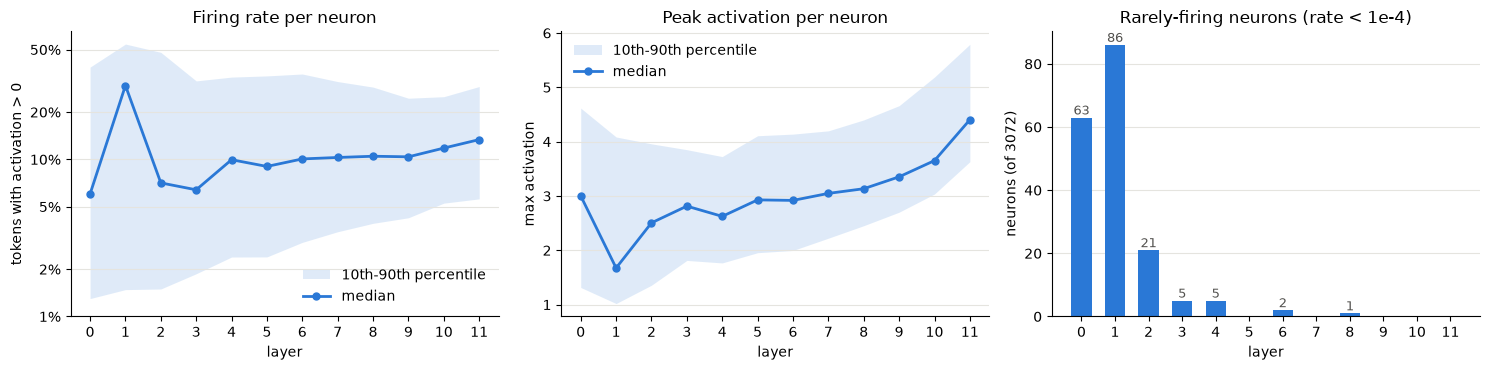

In [3]:
mlp = neurons[neurons.kind == "post"]
by = mlp.groupby("layer")
q = lambda col, p: by[col].quantile(p).to_numpy()
L = np.arange(12)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title, ylabel, log in [
    (axes[0], "frac_pos", "Firing rate per neuron", "tokens with activation > 0", True),
    (axes[1], "max", "Peak activation per neuron", "max activation", False),
]:
    ax.fill_between(L, q(col, 0.1), q(col, 0.9), color=C[0], alpha=0.15, lw=0, label="10th-90th percentile")
    ax.plot(L, q(col, 0.5), "o-", color=C[0], lw=2, ms=5, label="median")
    ax.set(title=title, xlabel="layer", ylabel=ylabel, yscale="log" if log else "linear")
    if log:
        ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5], ["1%", "2%", "5%", "10%", "20%", "50%"])
        ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.legend(frameon=False)
rare = by["frac_pos"].apply(lambda s: (s < 1e-4).sum()).to_numpy()
axes[2].bar(L, rare, color=C[0], width=0.6, zorder=2)
for l, n in zip(L, rare):
    if n:
        axes[2].text(l, n, str(n), ha="center", va="bottom", fontsize=9, color=INK2)
axes[2].set(title="Rarely-firing neurons (rate < 1e-4)", xlabel="layer", ylabel="neurons (of 3072)")
for ax in axes:
    ax.set_xticks(L)
    tidy(ax)
plt.tight_layout()

print("highest-peak neurons:")
print(mlp.nlargest(5, "max")[["layer", "unit", "max", "mean", "std", "frac_pos", "p999"]].to_string(index=False))

**Reading it.** Layers 0–2 hold most of the rarely-firing neurons (62, 87 and 21 of 3072). Layer 1 is the odd one out:
its median neuron fires on about 30% of tokens, more than twice the median of any other layer. Peak activations climb steadily
through the last layers, and the highest-peak neurons are all in layers 10–11.

## 3. A single neuron

`show_neuron(layer, unit)` prints the neuron's summary row, plots its activation histogram (from `histograms.npz`, on
an asinh axis: linear near 0, logarithmic in the tails) and lists its top-activating contexts with the token marked «like this».

blocks.9.mlp.hook_post unit 1000: mean -0.082, std 0.145, max 2.88, fires on 8.1% of tokens, p50 -0.117, p99 0.61, p99.9 1.36


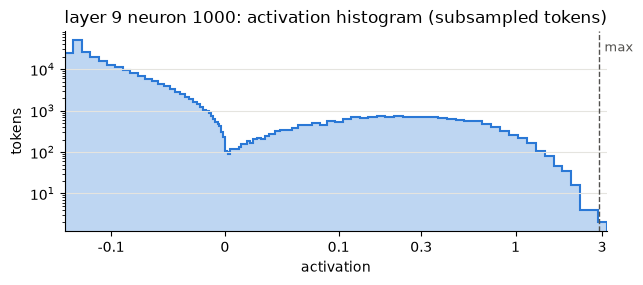

    2.88   in California during the Gold Rush. Joseph was the sixth« of» seven children born to
    2.88   one-of-a«-»kind wheelchair costumes,
    2.86  Closing Europe’s Borders Becomes Big Business⏎⏎This is the first of« a» two-part report
    2.81  hat ameliorated some of these problems. With that in mind, we turn« next» to one such open
    2.66  is paper needed to be submitted to my committee by early-January of« my» second year. Just
    2.64   of Appeal. The Court is made up of three individuals with« the» requisite legal and motor
    2.63  14 is still in there? Worth considering.⏎⏎Bronson Kaufusi is one of« a» trio of monster DE
    2.59  r continuing in assembly of five or more persons after it« has» been commanded to disperse
    2.59  s. The dragonhunter, then, can possibly be regarded as the first of« a» new set of special
    2.54  the Model 1925 (R75) was the R75A light machine gun with a quick«-»change barrel (produced


In [4]:
EDGES = hists["edges"]

def show_neuron(layer, unit, n=10, hook=None):
    hook = hook or f"blocks.{layer}.mlp.hook_post"
    row = neurons[(neurons.hook == hook) & (neurons.unit == unit)].iloc[0]
    print(f"{hook} unit {unit}: mean {row['mean']:.3f}, std {row['std']:.3f}, max {row['max']:.2f}, "
          f"fires on {row.frac_pos:.1%} of tokens, p50 {row.p50:.3f}, p99 {row.p99:.2f}, p99.9 {row.p999:.2f}")
    counts = hists[hook][unit]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5, fill=True, alpha=0.3)
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5)
    ax.axvline(row["max"], color=INK2, lw=1, ls="--")
    ax.annotate("max", (row["max"], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
    nz = np.nonzero(counts[1:-1])[0]
    lo, hi = EDGES[nz[0]], EDGES[nz[-1] + 1]
    ax.set_xscale("asinh", linear_width=0.05)
    ticks = [t for t in (-1, -0.1, 0, 0.1, 0.3, 1, 3, 10, 30, 100) if lo <= t <= hi]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.set(yscale="log", xlim=(lo, hi),
           title=f"layer {layer} neuron {unit}: activation histogram (subsampled tokens)", xlabel="activation", ylabel="tokens")
    tidy(ax)
    plt.show()
    t = topk[(topk.hook == hook) & (topk.unit == unit)].sort_values("rank").head(n)
    for v, ctx in zip(t.value, t.context):
        print(f"  {v:6.2f}  {ctx[-90:]}")

show_neuron(9, 1000)

blocks.11.mlp.hook_post unit 2378: mean 0.942, std 5.109, max 57.74, fires on 5.7% of tokens, p50 -0.001, p99 35.34, p99.9 47.49


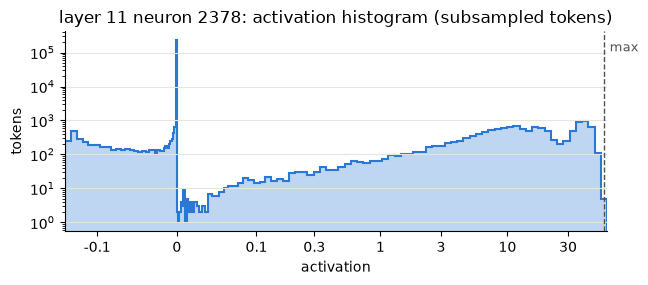

   57.74  ring presenting two times the resolution of the existing power ring .«⏎»⏎Installation of a
   56.41   to queue up armor pieces to equip by double clicking on multiple pieces«⏎»⏎Cooking Update
   56.38   eventually cast.⏎⏎Was considered for the role of Clayton in Tarzan (1999).«⏎»⏎Turned down
   56.38  rs⏎⏎Captain Toad: Treasure Tracker⏎⏎ACE COMBAT® Assault Horizon Legacy +«⏎»⏎Mario Party 10
   56.37  riels⏎⏎• Troll Axer⏎⏎• Troll Impaler«⏎»⏎• Dire Troll
   56.02   never returns to anything like the highest levels seen before Cabinet Office«⏎»⏎"The vast
   55.31  vial_relocate type trait. uninitialized_copy_ptr⏎⏎uninitialized_fill_ptr«⏎»⏎uninitialized_
   55.30  uld have kept the ball better tonight. I'm really pleased with the players though.«⏎»⏎"I'd
   55.08  p Pack⏎⏎iPhone Mockup⏎⏎Responsive Web Design Grid⏎⏎Smart Wearable Mockup«⏎»⏎The Responsive
   55.00   Troll Axer⏎⏎• Troll Impaler⏎⏎• Dire Troll Mauler⏎⏎• Trollkin Runebearer«⏎»⏎• Kriel


In [5]:
# The neuron with the largest peak activation in the last layer.
l11 = mlp[mlp.layer == 11].nlargest(1, "max").iloc[0]
show_neuron(11, int(l11.unit))

## 4. Statistical errors and the corpus systematic

`export` resamples the 8 shards with replacement (within each OpenWebText file) and pools them, giving a bootstrap
error on every unit's mean, std and firing rate (`*_err` columns), and on each layer's total variance and effective
dimension (§1). Whole shards are the resampling unit, so correlations between rows within a shard are accounted for.

**Corpus systematic: file 0 vs file 1.** With only 4 shards per file, each unit's error estimate is itself too noisy
for per-unit z-tests (z then follows a heavy-tailed distribution even when nothing differs). A robust test avoids
per-unit errors: compare the typical cross-file difference with the typical difference between two halves of the same
file, each in units of the unit's spread. Halves hold half the data, so their differences are divided by √2 to be
comparable. A ratio near 1 means the files differ no more than random splits do.

In [ ]:
mlp_mask = (neurons.kind == "post").to_numpy()
print("median bootstrap error             MLP neurons   residual dims")
for label, ratio in [("on the mean, in units of std", neurons.mean_err / neurons["std"]),
                     ("on the std, relative", neurons.std_err / neurons["std"]),
                     ("on the firing rate, relative", neurons.frac_pos_err / neurons.frac_pos.where(neurons.frac_pos > 0))]:
    print(f"  {label:32s} {np.nanmedian(ratio[mlp_mask]):10.4f}   {np.nanmedian(ratio[~mlp_mask]):12.4f}")

# Per-shard moments, in the same unit order as `neurons`.
sh = pd.read_parquet(ATLAS / "shards.parquet")
S, U = sh.shard.nunique(), len(neurons)
assert (sh.hook.to_numpy()[:U] == neurons.hook.to_numpy()).all() and (sh.unit.to_numpy()[:U] == neurons.unit.to_numpy()).all()
arr = lambda col: sh[col].to_numpy().reshape(S, U)
n_s, files_s = arr("n")[:, 0], arr("file")[:, 0]
moments_s = (n_s, arr("mean"), arr("m2"), arr("n_pos"))
pool = lambda mask: pooled_moments(np.asarray(mask, float)[None], *moments_s)

f0, f1 = np.unique(files_s)
spread = {"mean": neurons["std"].to_numpy(), "frac_pos": np.sqrt(neurons.frac_pos * (1 - neurons.frac_pos)).to_numpy()}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
print("\n|difference| / spread       cross-file   halves (÷√2)   ratio, median   ratio, 99th pct")
for ax, (col, title) in zip(axes, [("mean", "Mean activation"), ("frac_pos", "Firing rate")]):
    with np.errstate(divide="ignore", invalid="ignore"):
        cross = np.abs(pool(files_s == f0)[col][0] - pool(files_s == f1)[col][0]) / spread[col]
        halves = []
        for f in (f0, f1):
            idx = np.flatnonzero(files_s == f)
            for pair in ([0, 1], [0, 2], [0, 3]):  # the three ways to split 4 shards into two halves
                h = np.zeros(S); h[idx[pair]] = 1
                halves.append(np.abs(pool(h)[col][0] - pool((files_s == f) - h)[col][0]) / spread[col] / np.sqrt(2))
    for i, (m, label) in enumerate([(mlp_mask, "MLP neurons"), (~mlp_mask, "residual dims")]):
        if col == "frac_pos" and label == "residual dims":
            continue  # "> 0" is not meaningful for residual dimensions
        c = cross[m & np.isfinite(cross)]
        h = np.concatenate([x[m & np.isfinite(x)] for x in halves])
        print(f"{title[:12]:12s} {label:13s} {np.median(c):10.4f}   {np.median(h):10.4f}   {np.median(c) / np.median(h):12.2f}   "
              f"{np.quantile(c, 0.99) / np.quantile(h, 0.99):14.2f}")
        for vals, ls, which in [(h, "--", "halves of one file"), (c, "-", f"file {f0} vs file {f1}")]:
            v = np.sort(vals)
            ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], lw=2, ls=ls, label=f"{label}: {which}")
    ax.set(xscale="log", xlim=(1e-5, 3e-2), ylim=(0, 1), title=f"{title}: cross-file vs within-file differences",
           xlabel="|difference| / spread of the unit", ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()

print("\neffective dimension by file (± bootstrap within the file)")
print("layer  " + "  ".join(f"file {f:<10}" for f in resid["files"]) + "  both files")
for l in layers:
    cells = "  ".join(f"{resid['pr_file'][l, j]:5.1f} ± {resid['pr_err_file'][l, j]:<4.1f}  " for j in range(len(resid["files"])))
    print(f"{l:5d}  {cells}  {pr[l]:5.1f} ± {pr_err[l]:.1f}")

**Reading it.** Statistical errors are small: a neuron's mean is known to about 0.002 of its spread, which corresponds
to roughly 250k effective samples out of 1M tokens (tokens within documents and shards are correlated). The two
OpenWebText files differ no more than two halves of the same file (ratio about 1 in the median and the tail), and their
effective dimensions agree within about 1. That is expected: both files are random samples of the same corpus, so the
second file is a replicate, not a corpus systematic. A real corpus systematic needs a different corpus (FineWeb, code).

## 5. Regression check: pointers reproduce

Activations are a pure function of (weights, tokens), so the atlas stores exemplars as `(row, pos)` pointers. Recompute
a random sample of top-k entries and check that each stored value comes back.

In [6]:
model = HFGPT2("cpu")
sample = topk.sample(12, random_state=0)
worst = 0.0
for r in sample.itertuples():
    got = {}
    toks = torch.tensor(tokens[[r.row]].astype(np.int64))
    model.run(toks, {r.hook: lambda act: got.__setitem__("x", act[0, r.pos, r.unit].item())})
    worst = max(worst, abs(got["x"] - r.value) / max(abs(r.value), 1e-3))
    print(f"{r.hook:26s} unit {r.unit:4d} rank {r.rank:2d}: stored {r.value:9.4f}  recomputed {got['x']:9.4f}")
print(f"worst relative difference {worst:.1e}")
assert worst < 1e-3

/Users/ryan/Development/ioi-hydra/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 24394.11it/s]


blocks.4.hook_resid_pre    unit  690 rank  4: stored    7.1993  recomputed    7.1993
blocks.5.mlp.hook_post     unit 2543 rank  0: stored    3.0439  recomputed    3.0439
blocks.6.mlp.hook_post     unit 1456 rank 16: stored    2.0454  recomputed    2.0454
blocks.4.mlp.hook_post     unit 1705 rank  3: stored    3.0908  recomputed    3.0908
blocks.1.mlp.hook_post     unit  986 rank  7: stored    1.2298  recomputed    1.2298
blocks.8.hook_resid_pre    unit  766 rank 11: stored   11.2372  recomputed   11.2372
blocks.7.mlp.hook_post     unit 2477 rank 14: stored    2.6304  recomputed    2.6304
blocks.5.mlp.hook_post     unit 1987 rank 11: stored    1.8192  recomputed    1.8192
blocks.3.mlp.hook_post     unit 1081 rank  0: stored    3.4656  recomputed    3.4655
blocks.3.mlp.hook_post     unit 2653 rank 14: stored    2.9129  recomputed    2.9129
blocks.2.mlp.hook_post     unit 1546 rank 15: stored    1.6421  recomputed    1.6421
blocks.9.hook_resid_pre    unit  715 rank  7: stored   15.5070  r